# Entendimiento de los datos RaSA

## Configuración e importe de paquetes

In [4]:
import os
import sys

# En la máquina virtual ya está todo instalado
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
IN_CODESPACES = os.environ.get('CODESPACES') == 'true'

if IN_COLAB or IN_CODESPACES:
    %pip install -q pyspark==4.2.0 pandas==2.3.3 numpy==2.5.3 pyarrow==25.0.1 matplotlib==3.11.2 fg-data-profiling==4.20.0 scipy==1.18.1 seaborn==0.13.2

if IN_COLAB:
    # Spark 4 requiere Java 17 o superior
    !apt-get install -y -qq openjdk-21-jdk-headless > /dev/null
    os.environ['JAVA_HOME'] = '/usr/lib/jvm/java-21-openjdk-amd64'

ENVIRONMENT = 'colab' if IN_COLAB else 'codespaces' if IN_CODESPACES else 'local'
print(f'Entorno detectado: {ENVIRONMENT}')

from pyspark.sql import SparkSession
from pyspark.sql import functions
from pyspark.sql.types import StructType
from pyspark.sql.types import FloatType, StringType, IntegerType, DateType
from pyspark.sql.functions import udf, col, length, isnan, when, count
import pyspark.sql.functions as f
from datetime import datetime
from pyspark.sql import types as t

from data_profiling import ProfileReport

import matplotlib.pyplot as plt
import numpy as np

Entorno detectado: local


### Configuración del controlador e inicio de sesión Spark

In [5]:
from pathlib import Path
import urllib.request

CONNECTOR_VERSION = '9.7.0'
CONNECTOR_URL = ('https://repo1.maven.org/maven2/com/mysql/mysql-connector-j/'
                 f'{CONNECTOR_VERSION}/mysql-connector-j-{CONNECTOR_VERSION}.jar')

def obtener_jar_mysql():
    env_path = os.environ.get('CONNECTOR_J_PATH', '')
    if env_path and Path(env_path).is_file():
        return Path(env_path)
    jar = Path.home() / '.miid4103' / 'jars' / f'mysql-connector-j-{CONNECTOR_VERSION}.jar'
    if not jar.exists():
        jar.parent.mkdir(parents=True, exist_ok=True)
        print(f'Descargando MySQL Connector/J {CONNECTOR_VERSION}...')
        parcial = jar.with_suffix('.part')
        urllib.request.urlretrieve(CONNECTOR_URL, parcial)
        parcial.replace(jar)
    return jar

MYSQL_JAR = obtener_jar_mysql()
MYSQL_JAR_URI = MYSQL_JAR.as_uri()
print(f'Conector JDBC: {MYSQL_JAR}')

Conector JDBC: C:\Users\mp.escobar\.miid4103\jars\mysql-connector-j-9.7.0.jar


In [6]:
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
# Necesario en Windows si Python está en C:\Program Files
import pyspark
os.environ.setdefault('SPARK_HOME', os.path.dirname(pyspark.__file__))
# Spark 4.2 en Windows requiere HADOOP_HOME
if os.name == 'nt' and 'HADOOP_HOME' not in os.environ:
    hadoop_home = Path.home() / '.miid4103' / 'hadoop'
    (hadoop_home / 'bin').mkdir(parents=True, exist_ok=True)
    (hadoop_home / 'bin' / 'winutils.exe').touch()
    os.environ['HADOOP_HOME'] = str(hadoop_home)

spark = (SparkSession.builder
         .master('local[*]')
         .appName('MIID4103-NB02')
         .config('spark.driver.host', '127.0.0.1')
         .config('spark.jars', MYSQL_JAR_URI)
         .config('spark.sql.execution.arrow.pyspark.enabled', 'true')
         .config('spark.sql.shuffle.partitions', '8')
         .config('spark.ui.enabled', 'false')
         .config('spark.ui.showConsoleProgress', 'false')
         .config('spark.sql.ansi.enabled', 'false')    # comportamiento de Spark 3.5
         .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')

In [7]:
db_host = '157.253.236.120'
db_port = 8080
db_user = 'DB_202615_mp_escobar'
db_psswd = '201823974'

if not db_user or not db_psswd:
    raise ValueError('Complete db_user y db_psswd antes de continuar')
jdbc_opciones = 'useConfigs=maxPerformance&connectTimeout=10000&socketTimeout=600000'
db_connection_string = f'jdbc:mysql://{db_host}:{db_port}/RaSaTransaccional?{jdbc_opciones}'

# En Colab, suba los archivos a /content/
PATH = '/content/' if ENVIRONMENT == 'colab' else './'

OUT = Path('/content/salidas') if ENVIRONMENT == 'colab' else Path.home() / 'MIID4103' / 'salidas'
OUT.mkdir(parents=True, exist_ok=True)

## Perfilamiento de los datos

### Conexión a fuente de datos y acceso a los datos

#### Conexión a fuente de datos


In [8]:
def obtener_dataframe_de_bd(db_connection_string, sql, db_user, db_psswd):
    df_bd = spark.read.format('jdbc')\
        .option('url', db_connection_string) \
        .option('dbtable', sql) \
        .option('user', db_user) \
        .option('password', db_psswd) \
        .option('driver', 'com.mysql.cj.jdbc.Driver') \
        .load()
    return df_bd.cache()

#### Cargue de datos

In [9]:
sql_areas_servicio = 'RaSaTransaccional.FuenteAreasDeServicio_Copia_E'

sql_condiciones_pago = 'RaSaTransaccional.FuenteCondicionesDePago_Copia_E'

sql_planes_beneficio = 'RaSaTransaccional.FuentePlanesBeneficio_Copia_E'

sql_tipos_beneficio = 'RaSaTransaccional.FuenteTiposBeneficio_Copia_E'

In [10]:
#Se cargan los dataframes desde la base de datos
areas_servicio = obtener_dataframe_de_bd(db_connection_string, sql_areas_servicio, db_user, db_psswd)
condiciones_pago = obtener_dataframe_de_bd(db_connection_string, sql_condiciones_pago, db_user, db_psswd)
planes_beneficio = obtener_dataframe_de_bd(db_connection_string, sql_planes_beneficio, db_user, db_psswd)
tipos_beneficio = obtener_dataframe_de_bd(db_connection_string, sql_tipos_beneficio, db_user, db_psswd)

### Entendimiento general de datos

In [11]:
areas_servicio.show(5)

+------------------+--------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|IdAreaDeServicio_T|NombreAreaDeServicio|IdGeografia_T|          Condado|    Estado|PoblacionAct| Area|Densidad|Fecha|
+------------------+--------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|         100622017|New Jersey - Medi...|        34005|Burlington County|New Jersey|    464269.0|805.0|   577.0| 2017|
|         101012018|New Jersey - Medi...|        34031|   Passaic County|New Jersey|    518117.0|185.0|  2801.0| 2018|
|          10132017|BlueOptions16842F...|        12031|     Duval County|   Florida|    999935.0|774.0|  1292.0| 2017|
|         101982018|New Jersey - Medi...|        34003|    Bergen County|New Jersey|    953819.0|234.0|  4076.0| 2018|
|         102012017|New Jersey - Medi...|        34021|    Mercer County|New Jersey|    385898.0|226.0|  1708.0| 2017|
+------------------+--------------------+-------

In [12]:
areas_servicio.schema

StructType([StructField('IdAreaDeServicio_T', IntegerType(), True), StructField('NombreAreaDeServicio', StringType(), True), StructField('IdGeografia_T', IntegerType(), True), StructField('Condado', StringType(), True), StructField('Estado', StringType(), True), StructField('PoblacionAct', FloatType(), True), StructField('Area', FloatType(), True), StructField('Densidad', FloatType(), True), StructField('Fecha', IntegerType(), True)])

En la tabla áreas de servicio se encuentra información relacionada con el área de servicio, su ubicación, tamaño, población y fecha de creación. La información del área proviene de las columnas IdAreaDeServicio_T (identificador del área) y NombreAreaDeServicio (nombre del área), el identificador del condado corrresponde a IdGeografia_T y su nombre y estado están en las columnas Condado y Estado, respectivamente. PoblacionAct corresponde al número de habitantes actuales del área de servicio, Area al área en millas cuadradas, Densidad a número de habitantes por milla cuadrada y Fecha a la fecha de creación del área de servicio. 

In [13]:
condiciones_pago.show(5)

+---------------------+--------------------+--------+
|IdCondicionesDePago_T|         Descripcion|    Tipo|
+---------------------+--------------------+--------+
|                  187|Copay with deduct...|  Copago|
|                  204|       Copay per Day|  Copago|
|                   45|         Coinsurance|Coseguro|
|                   85|Copay per Day bef...|  Copago|
|                   18|No Charge after d...|Coseguro|
+---------------------+--------------------+--------+
only showing top 5 rows


In [14]:
condiciones_pago.schema

StructType([StructField('IdCondicionesDePago_T', IntegerType(), True), StructField('Descripcion', StringType(), True), StructField('Tipo', StringType(), True)])

La tabla de condiciones de pago contiene el identificador de la condición de pago en la columna IdCondicionesDePago_T, su descripción en la columna Descripcion y su tipo en Tipo.

In [13]:
planes_beneficio.show(5)

+-----------------+------------------+-------------------------+---------------------------+-----------------+-----------------+----------+-------------+-----------+-------------+--------------+
|IdTipoBeneficio_T|IdAreaDeServicio_T|IdCondicionDePagoCopago_T|IdCondicionDePagoCoseguro_T|IdNivelServicio_T|         IdPlan_T|     Fecha|IdProveedor_T|valorCopago|valorCoseguro|cantidadLimite|
+-----------------+------------------+-------------------------+---------------------------+-----------------+-----------------+----------+-------------+-----------+-------------+--------------+
|              640|          10382017|                       34|                         27|                3|16842FL0070128-03|2017-12-31|        16842|          0|           50|            35|
|              225|          31512017|                      238|                         45|                2|29418TX0140002-04|2017-12-31|        29418|          0|            0|          NULL|
|              190|      

In [16]:
planes_beneficio.schema

StructType([StructField('IdTipoBeneficio_T', LongType(), True), StructField('IdAreaDeServicio_T', LongType(), True), StructField('IdCondicionDePagoCopago_T', IntegerType(), True), StructField('IdCondicionDePagoCoseguro_T', IntegerType(), True), StructField('IdNivelServicio_T', IntegerType(), True), StructField('IdPlan_T', StringType(), True), StructField('Fecha', StringType(), True), StructField('IdProveedor_T', IntegerType(), True), StructField('valorCopago', IntegerType(), True), StructField('valorCoseguro', IntegerType(), True), StructField('cantidadLimite', IntegerType(), True)])

La tabla de planes contiene información del identificador del tipo de beneficio (IdTipoBeneficio_T), del identificador del área de servicio (IdAreaDeServicio_T), del identificador de la condicion de pago Copago (IdCondicionDePagoCopago_T), identificador de la condicion de pago Coseguro (IdCondicionDePagoCoseguro_T), identificador del nivel de servicio (IdNivelServicio_T), identificador del plan (IdPlan_T), la fecha de oferta del beneficio para ese plan (Fecha), identificador del proveedor del plan (IdProveedor_T), valor del copago (valorCopago), valor del coseguro (valorCoseguro) y la cantidad límite del tipo de beneficio, es decir, la cantidad máxima de unidades del beneficio a las cuales el usuario puede acceder en un año (cantidadLimite).

In [17]:
tipos_beneficio.show(5)

+-----------------+--------------------+--------------------+-----+---------------------+-----------------------+----------------------------------------+---------------------------------------+-----+
|IdTipoBeneficio_T|              Nombre|     UnidadDelLimite|EsEHB|EstaCubiertaPorSeguro|TieneLimiteCuantitativo|ExcluidoDelDesembolsoMaximoDentroDeLaRed|ExcluidoDelDesembolsoMaximoFueraDeLaRed|Fecha|
+-----------------+--------------------+--------------------+-----+---------------------+-----------------------+----------------------------------------+---------------------------------------+-----+
|              565|Nutritional Couns...|                    |   No|                  Yes|                     No|                                      No|                                    Yes| 2017|
|              795|Rehabilitative Sp...|Days per Benefit ...|  Yes|                  Yes|                    Yes|                                      No|                                    Yes| 2

In [18]:
tipos_beneficio.schema

StructType([StructField('IdTipoBeneficio_T', IntegerType(), True), StructField('Nombre', StringType(), True), StructField('UnidadDelLimite', StringType(), True), StructField('EsEHB', StringType(), True), StructField('EstaCubiertaPorSeguro', StringType(), True), StructField('TieneLimiteCuantitativo', StringType(), True), StructField('ExcluidoDelDesembolsoMaximoDentroDeLaRed', StringType(), True), StructField('ExcluidoDelDesembolsoMaximoFueraDeLaRed', StringType(), True), StructField('Fecha', IntegerType(), True)])

La tabla de tipos de beneficio contiene información del identificador del tipo de beneficio (IdTipoBeneficio_T), del nombre del tipo de beneficio (Nombre), de la unidad en la que se expresa el límite (UnidadDelLimite), si es beneficio esencial de salud (EsEHB), si el seguro lo cubre (EstaCubiertaPorSeguro), si tiene límite cuantitativo (TieneLimiteCuantitativo), si está excluido del desembolso máximo dentro de la red (ExcluidoDelDesembolsoMaximoDentroDeLaRed), si está excluido del desembolso máximo fuera de la red (ExcluidoDelDesembolsoMaximoFueraDeLaRed) y de la fecha en que se define el tipo de beneficio (Fecha).

**¿Qué es una fila de cada fuente compartida?**

1) Una fila de FuenteAreasDeServicio_Copia_E representa un área de servicio en un condado con cierta población, área y densidad. 
2) Una fila de FuenteCondicionesDePago_Copia_E representa una condición de pago con su descripción y tipo.
3) Una fila de FuentePlanesBeneficio_Copia_E representa un plan con un tipo de beneficio, un área de servicio, una condición de pago Copago, una condición de pago Coseguro, un proveedor del plan y un nivel de servicio.
4) Una fila de FuenteTiposBeneficio_Copia_E representa un tipo de beneficio e incluye las condiciones asociadas a su beneficio, cobertura del seguro, límite y desembolsos dentro y fuera de la red.

In [14]:
print((areas_servicio.count(), len(areas_servicio.columns)),(condiciones_pago.count(), len(condiciones_pago.columns)))
print((planes_beneficio.count(), len(planes_beneficio.columns)),(tipos_beneficio.count(), len(tipos_beneficio.columns)))

(188815, 9) (31, 3)
(36036, 11) (849, 9)


En total se cuentan con 188815 áreas de servicio, 31 condiciones de pago, 36036 planes y 849 tipos de beneficios. Se tienen 32 variables en total a revisar, de las cuales 3 corresponden a fechas, 10 corresponden a identificadores númericos, 13 a cadenas de carácteres y las demás a variables númericas.

### Revisión de reglas de negocio


1) Las áreas de servicios reportadas cubren todos los condados del país

In [63]:
areas_servicio.select('IdGeografia_T').distinct().count()

4252

Para corroborar que esta regla de negocio es correcta se requiere de una tabla que contenga todos los condados del país con sus identificadores, dado que con la información en las fuentes brindadas por el negocio no es posible determinar si los 4252 valores únicos encontrados para el identificador del condado corresponden a 4252 condados que tiene el país en total.

2. Los tipos de beneficios con límite cuantitativo deben tener una cantidad límite diferente de cero en los planes que los ofrecen.

In [64]:
tipos_beneficio.groupBy('TieneLimiteCuantitativo').count().show()

+-----------------------+-----+
|TieneLimiteCuantitativo|count|
+-----------------------+-----+
|                     No|  542|
|                    Yes|  271|
|                     Si|   12|
|                   Nein|   24|
+-----------------------+-----+



- Se evidencia que hay diferentes valores que indican que el tipo de beneficio sí tiene límite cuantitativo (Yes y Si) ¿Cuál de ellos es el correcto para el negocio?
- Hay dos valores que indican que no se tiene límite cuantitativo (No y Nein) ¿Cuál de ellos es el correcto para el negocio?

In [65]:
p = planes_beneficio.alias('p')
t = tipos_beneficio.alias('t')

verificar_limites = p.join(t, col('p.IdTipoBeneficio_T') == col('t.IdTipoBeneficio_T'), 'left').select(
    'p.IdPlan_T', 'p.IdTipoBeneficio_T', 't.TieneLimiteCuantitativo', 'p.CantidadLimite', 
    col('p.Fecha').alias('p.Fecha_plan'),
    col('t.Fecha').alias('Fecha_TipoBeneficio'))

verificar_limites.show(24)

+-----------------+-----------------+-----------------------+--------------+------------+-------------------+
|         IdPlan_T|IdTipoBeneficio_T|TieneLimiteCuantitativo|CantidadLimite|p.Fecha_plan|Fecha_TipoBeneficio|
+-----------------+-----------------+-----------------------+--------------+------------+-------------------+
|16842FL0070128-03|              640|                     No|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                    Yes|            35|  2017-12-31|               2018|
|16842FL0070128-03|              640|                    Yes|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                     No|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                     No|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                     No|            35|  2017-12-31|               2018|
|16842FL00

In [66]:
verificar_limites.filter(col('IdPlan_T') == '16842FL0070128-03').filter(col('Fecha_TipoBeneficio') == '2017') \
.filter(col('IdTipoBeneficio_T') == '640') \
.show()

+-----------------+-----------------+-----------------------+--------------+------------+-------------------+
|         IdPlan_T|IdTipoBeneficio_T|TieneLimiteCuantitativo|CantidadLimite|p.Fecha_plan|Fecha_TipoBeneficio|
+-----------------+-----------------+-----------------------+--------------+------------+-------------------+
|16842FL0070128-03|              640|                     No|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                    Yes|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                     No|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                     No|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                    Yes|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                    Yes|            35|  2017-12-31|               2017|
|16842FL00

In [67]:
verificar_limites.filter(col('IdPlan_T') == '16842FL0070128-03').filter(col('Fecha_TipoBeneficio') == '2017') \
.filter(col('IdTipoBeneficio_T') == '640') \
.show()

+-----------------+-----------------+-----------------------+--------------+------------+-------------------+
|         IdPlan_T|IdTipoBeneficio_T|TieneLimiteCuantitativo|CantidadLimite|p.Fecha_plan|Fecha_TipoBeneficio|
+-----------------+-----------------+-----------------------+--------------+------------+-------------------+
|16842FL0070128-03|              640|                     No|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                    Yes|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                     No|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                     No|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                    Yes|            35|  2017-12-31|               2017|
|16842FL0070128-03|              640|                    Yes|            35|  2017-12-31|               2017|
|16842FL00

In [68]:
verificar_limites.filter(col('IdPlan_T') == '16842FL0070128-03').filter(col('Fecha_TipoBeneficio') == '2017') \
.filter(col('IdTipoBeneficio_T') == '640').filter(col('TieneLimiteCuantitativo') == 'Yes') \
.count()

30

In [69]:
verificar_limites.filter(col('IdPlan_T') == '16842FL0070128-03')\
.filter(col('IdTipoBeneficio_T') == '275') \
.show()

+-----------------+-----------------+-----------------------+--------------+------------+-------------------+
|         IdPlan_T|IdTipoBeneficio_T|TieneLimiteCuantitativo|CantidadLimite|p.Fecha_plan|Fecha_TipoBeneficio|
+-----------------+-----------------+-----------------------+--------------+------------+-------------------+
|16842FL0070128-03|              275|                     No|             1|  2017-12-31|               2017|
|16842FL0070128-03|              275|                     No|             1|  2017-12-31|               2018|
|16842FL0070128-03|              275|                    Yes|             1|  2017-12-31|               2017|
|16842FL0070128-03|              275|                    Yes|             1|  2017-12-31|               2017|
|16842FL0070128-03|              275|                    Yes|             1|  2017-12-31|               2017|
|16842FL0070128-03|              275|                    Yes|             1|  2017-12-31|               2017|
|16842FL00

Se conoce que los planes ofrecidos brindan una serie de beneficios con unas condiciones que pueden cambiar a través del tiempo, como si tiene límite cuantitativo o no. El negocio está interesado en manejar la historia de los planes con sus condiciones, sin embargo, no es posible determinar si el beneficio de un plan tiene un límite cuantitativo debido a los múltiples valores que puede tener el tipo de beneficio para TieneLimiteCuantitativo. Por ejemplo, para el plan con ID 16842FL0070128-03 del 2017-12-31, un tipo de beneficio asociado tiene identificador 640. El identificador 640 en la tabla de tipos de beneficio tiene 66 registros para el año 2017, 30 de ellos con valor Yes para TieneLimiteCuantitativo. Ese mismo plan tiene también asociado el tipo de beneficio con identificador 275, y para los años 2017 y 2018 este tipo de beneficio tiene varios registros con diferentes valores para TieneLimiteCuantitativo, por lo cual no es posible determinar si los beneficios del plan deberían tener o no un límite cuantitativo y, por tanto, no es posible corroborar que si el beneficio tiene un límite este deba tener cantidad límite diferente de 0. Además, se desconoce cómo se debe relacionar la fecha de oferta del beneficio para un plan con el año en el que se definió el tipo de servicio.

3. Las fuentes FuenteAreasDeServicio_Copia_E y FuenteTiposBeneficio_Copia_E comparten información de los años 2017 al 2019

In [70]:
areas_servicio.select('Fecha').distinct().show()

+-----+
|Fecha|
+-----+
| 1800|
| 2017|
| 2018|
+-----+



In [71]:
tipos_beneficio.select('Fecha').distinct().show()

+-----+
|Fecha|
+-----+
| 2017|
| 2018|
+-----+



Ninguna de las dos fuentes comparte información más allá del año 2018. También se evidencia que existen registros de áreas de servicio con fecha de creación 1800. ¿Esto es correcto para el negocio?

4. La empresa comparte 5409 áreas de servicios y 170 tipos de beneficios.

In [72]:
areas_servicio.select('IdAreaDeServicio_T').distinct().count()

5410

In [73]:
areas_servicio.select('IdAreaDeServicio_T').filter(col('IdAreaDeServicio_T').isNotNull()).distinct().count()

5409

In [74]:
areas_servicio.select('NombreAreaDeServicio').distinct().count()

5412

In [75]:
tipos_beneficio.select('IdTipoBeneficio_T').distinct().count()

178

In [76]:
tipos_beneficio.select('IdTipoBeneficio_T').filter(col('IdTipoBeneficio_T').isNotNull()).distinct().count()

178

Existen 5409 IDs únicos para IdAreaDeServicio_T sin contar el valor nulo existente en la tabla y cada ID puede tener varios nombres asociados. En total hay 5412 nombres de área de servicio únicos. Por otro lado, existen 178 valores únicos para IdTipoBeneficio_T, 8 valores más que lo que indica la regla de negocio.

5. El valor máximo Copago y Coseguro para el año 2018 es respectivamente 3300 y 100.

In [83]:
planes_beneficio.select('Fecha').distinct().show()

+-----------+
|      Fecha|
+-----------+
| 1920-12-31|
| 2018-12-31|
|Dec 31,2018|
|Dec 31,2017|
| 2017-12-31|
+-----------+



In [26]:
from pyspark.sql.functions import to_date, year, coalesce, max

planes_beneficio = planes_beneficio.withColumn('Fecha_convertida', coalesce(to_date(col('Fecha'), 'yyyy-MM-dd'),
        to_date(col('Fecha'), 'MMM dd,yyyy')))

planes_beneficio.filter(year(col('Fecha_convertida')) == 2018).agg(max(col('valorCopago')).alias('Maximo_2018')).show()

+-----------+
|Maximo_2018|
+-----------+
|       3500|
+-----------+



In [86]:
planes_beneficio.filter(year(col('Fecha_convertida')) == 2018).agg(max(col('valorCoseguro')).alias('Maximo_2018')).show()

+-----------+
|Maximo_2018|
+-----------+
|        100|
+-----------+



- Se observa que existen formatos diferentes para la fecha de oferta del plan, ¿cuál es el correcto?
- Solo se cumple la regla del negocio para el máximo valor Coseguro del 2018. El máximo valor Copago del 2018 encontrado es 3500, no 3300.

6. Se comparte información de 301 planes para 2017 y de 422 para el año 2018.

In [27]:
from pyspark.sql.functions import countDistinct

planes_beneficio.filter(year(col('Fecha_convertida')) == 2017).agg(countDistinct('IdPlan_T').alias('Unicos_2017')).show()

+-----------+
|Unicos_2017|
+-----------+
|        203|
+-----------+



In [89]:
planes_beneficio.filter(year(col('Fecha_convertida')) == 2018).agg(countDistinct('IdPlan_T').alias('Unicos_2018')).show()

+-----------+
|Unicos_2018|
+-----------+
|        287|
+-----------+



No se cumple con la regla de negocio. Se encontraron 203 identificadores únicos de plan para el 2017 y 287 para el 2018.

7. Existen 15 y 5 diferentes condiciones de copago y coseguro respectivamente.

In [94]:
condiciones_pago.groupBy('Tipo').agg(countDistinct('IdCondicionesDePago_T').alias('Conteo')).show()

+-------------+------+
|         Tipo|Conteo|
+-------------+------+
|          NaN|     1|
|SinTipoCopago|     1|
|  Coseguridad|     1|
|       Copago|    14|
|     Coseguro|     5|
|     Copagado|     1|
+-------------+------+



Asumiendo que Copagado y Copago tienen el mismo significado, existen 15 condiciones de copago. Existen 5 condiciones de Coseguro, pero si Coseguridad tiene el mismo significado entonces existirían 6 condiciones de coseguro. Se debe consultar al negocio si Coseguridad corresponde a Coseguro y si Copagado corresponde a Copago.

### Análisis descriptivo


In [95]:
areas_servicio.summary().show()

+-------+--------------------+--------------------+------------------+----------------+-------+-------------------+------------------+-----------------+------------------+
|summary|  IdAreaDeServicio_T|NombreAreaDeServicio|     IdGeografia_T|         Condado| Estado|       PoblacionAct|              Area|         Densidad|             Fecha|
+-------+--------------------+--------------------+------------------+----------------+-------+-------------------+------------------+-----------------+------------------+
|  count|              182527|              188815|            182437|          188815| 188815|             188815|            186408|           186408|            188815|
|   mean|5.5661602010935366E7|                NULL| 42946.06266820875|            NULL|   NULL|4.147959039464555E7| 770.9518851122269|276.0979410754903|2010.2215554908244|
| stddev|3.0402410466496132E7|                NULL|32489.478070072095|            NULL|   NULL|5.943835891771832E8|1263.4887340485252|851.32

Se observa que el número de habitantes actuales de las áreas de servicio tiene un mínimo de 82 y un máximo de 47.280.300.000, aunque resalta que el 75% de las áreas tienen poblaciones menores a 110686 personas. Este valor máximo se revisará en un diagrama de caja para verificar si se trata de un outlier, aunque puede corresponder al área con la máxima densidad y la máxima área en millas cuadradas. Resalta de nuevo también el valor mínimo para la fecha de creación del área de servicio (1800). 

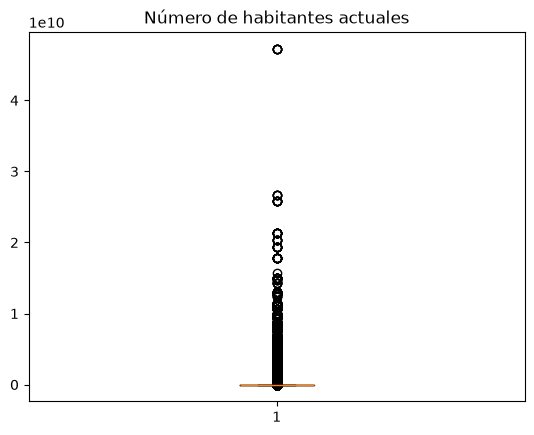

In [96]:
%matplotlib inline
import matplotlib.pyplot as plt

fig1, ax1 = plt.subplots()
ax1.set_title('Número de habitantes actuales')
data_poblacion = [row[0] for row in areas_servicio.select('PoblacionAct').dropna().collect()]
ax1.boxplot(data_poblacion)
plt.show()

In [99]:
areas_servicio.filter(col('PoblacionAct') == 47280300000).show()

+------------------+--------------------+-------------+-------------+------+------------+------+--------+-----+
|IdAreaDeServicio_T|NombreAreaDeServicio|IdGeografia_T|      Condado|Estado|PoblacionAct|  Area|Densidad|Fecha|
+------------------+--------------------+-------------+-------------+------+------------+------+--------+-----+
|          29152018|Ambetter from Sup...|        48201|Harris County| Texas|  4.72803E10|1729.0|  2735.0| 2018|
|          27322018|Community Gulf Co...|        48201|Harris County| Texas|  4.72803E10|1729.0|  2735.0| 2018|
|          25712018|Community Gulf Co...|        48201|Harris County| Texas|  4.72803E10|1729.0|  2735.0| 2018|
|          29152018|Ambetter from Sup...|        48201|Harris County| Texas|  4.72803E10|1729.0|  2735.0| 2018|
|          25712018|Community Gulf Co...|        48201|Harris County| Texas|  4.72803E10|1729.0|  2735.0| 2018|
+------------------+--------------------+-------------+-------------+------+------------+------+--------

In [107]:
areas_servicio.filter(col('PoblacionAct') == 0).show()

+------------------+--------------------+-------------+-------+------+------------+----+--------+-----+
|IdAreaDeServicio_T|NombreAreaDeServicio|IdGeografia_T|Condado|Estado|PoblacionAct|Area|Densidad|Fecha|
+------------------+--------------------+-------------+-------+------+------------+----+--------+-----+
+------------------+--------------------+-------------+-------+------+------------+----+--------+-----+



Hay múltiples áreas con una población de 47.280.300.000 personas, ninguna corresponde al área con la máxima densidad poblacional ni con la máxima área en millas cuadradas, ¿esto tiene sentido, o se trata de un error de digitación? Si el área en millas cuadradas es 1729 y hay 2735 habitantes por milla cuadrada, entonces el número de habitantes debería ser 4.728.815. Resalta también que existen duplicados en áreas de servicio.

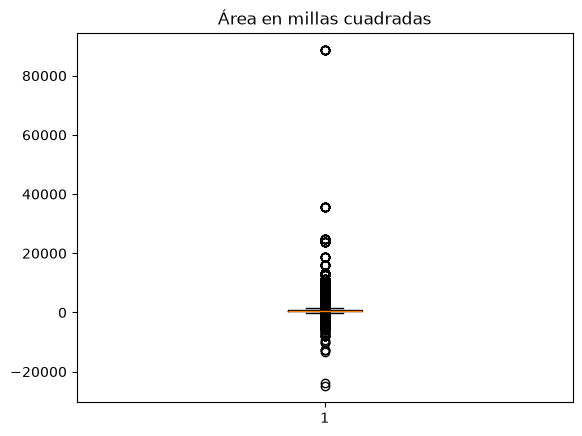

In [105]:
fig1, ax1 = plt.subplots()
ax1.set_title('Área en millas cuadradas')
data_area = [row[0] for row in areas_servicio.select('Area').dropna().collect()]
ax1.boxplot(data_area)
plt.show()

In [106]:
areas_servicio.filter(col('Area') == 88824).show()

+------------------+--------------------+-------------+-------------------+------+------------+-------+--------+-----+
|IdAreaDeServicio_T|NombreAreaDeServicio|IdGeografia_T|            Condado|Estado|PoblacionAct|   Area|Densidad|Fecha|
+------------------+--------------------+-------------+-------------------+------+------------+-------+--------+-----+
|          20982017|Alaska21989AK0130...|         2185|North Slope Borough|Alaska|     10972.0|88824.0|     0.0| 2017|
|          86322018|Alaska73836AK0700...|         2185|North Slope Borough|Alaska|     10972.0|88824.0|     0.0| 2018|
|          86342017|Alaska73836AK0700...|         2185|North Slope Borough|Alaska|     10972.0|88824.0|     0.0| 2017|
|          21002017|Alaska21989AK0130...|         2185|North Slope Borough|Alaska|     10972.0|88824.0|     0.0| 2017|
|          50112017|PBCBSAK Service A...|         2185|North Slope Borough|Alaska|     10972.0|88824.0|     0.0| 2017|
|          50122018|PBCBSAK Service A...|       

In [108]:
areas_servicio.filter(col('Area') == 0).show()

+------------------+--------------------+-------------+-------+------+------------+----+--------+-----+
|IdAreaDeServicio_T|NombreAreaDeServicio|IdGeografia_T|Condado|Estado|PoblacionAct|Area|Densidad|Fecha|
+------------------+--------------------+-------------+-------+------+------------+----+--------+-----+
+------------------+--------------------+-------------+-------+------+------------+----+--------+-----+



Se observa que existen valores negativos para el área en millas cuadradas, lo cual no tiene sentido. También se observa que el valor máximo es un outlier que se aleja notablemente de los demás datos, y está asociado a múltiples áreas de servicio.

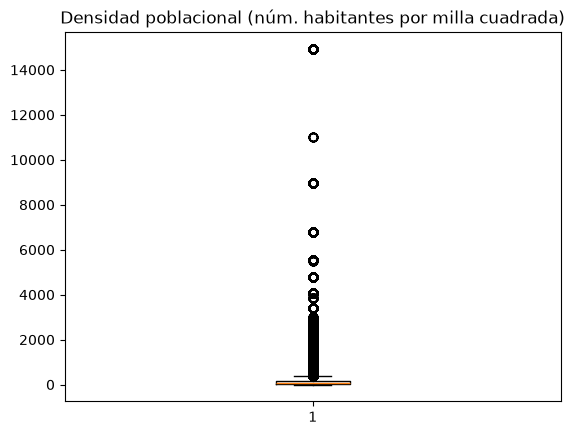

In [109]:
fig1, ax1 = plt.subplots()
ax1.set_title('Densidad poblacional (núm. habitantes por milla cuadrada)')
data_densidad = [row[0] for row in areas_servicio.select('Densidad').dropna().collect()]
ax1.boxplot(data_densidad)
plt.show()

In [112]:
areas_servicio.filter(col('Densidad') == 0).count()

769

In [113]:
areas_servicio.filter(col('Densidad') == 0).show()

+------------------+--------------------+-------------+--------------------+------------+------------+-------+--------+-----+
|IdAreaDeServicio_T|NombreAreaDeServicio|IdGeografia_T|             Condado|      Estado|PoblacionAct|   Area|Densidad|Fecha|
+------------------+--------------------+-------------+--------------------+------------+------------+-------+--------+-----+
|          23132018|Statewide Medical...|        30011|       Carter County|     Montana|      1428.0| 3340.0|     0.0| 2018|
|          11922018|Molina Marketplac...|        35021|      Harding County|  New Mexico|       639.0| 2126.0|     0.0| 2018|
|          23292018|Statewide Medical...|        30011|       Carter County|     Montana|      1428.0| 3340.0|     0.0| 2018|
|          23362018|Statewide Medical...|        30033|     Garfield County|     Montana|      1209.0| 4668.0|     0.0| 2018|
|          34832018|South Dakota Serv...|        46063|      Harding County|South Dakota|      1327.0| 2671.0|     0.0

Existen 769 registros de áreas de servicio con densidad poblacional igual a 0. Para estas áreas la población actual es menor al área en millas cuadradas y la densidad debería ser un decimal que empieza con 0, ¿el negocio redondea a 0 la densidad para estos casos?

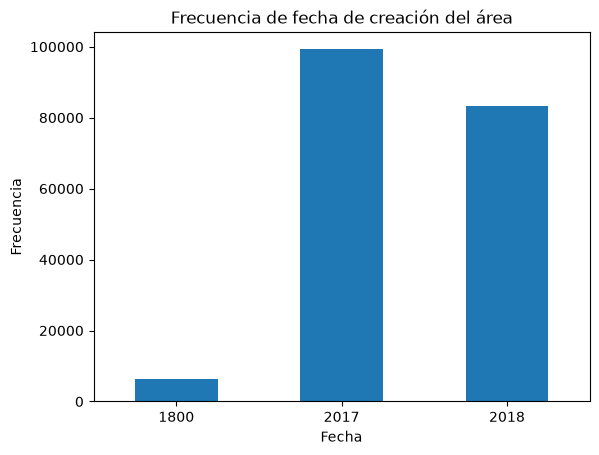

In [117]:
areas_servicio.toPandas()['Fecha'] \
    .value_counts() \
    .sort_index() \
    .plot(kind='bar')

plt.xlabel('Fecha')
plt.ylabel('Frecuencia')
plt.title('Frecuencia de fecha de creación del área')
plt.xticks(rotation=0)
plt.show()

La fecha 1800 es la menos frecuente dentro de las áreas de servicio, la más frecuente es 2017.

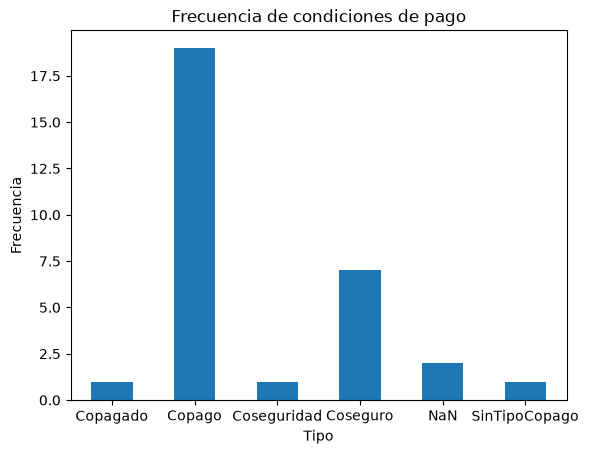

In [119]:
condiciones_pago.toPandas()['Tipo'] \
    .value_counts() \
    .sort_index() \
    .plot(kind='bar')

plt.xlabel('Tipo')
plt.ylabel('Frecuencia')
plt.title('Frecuencia de condiciones de pago')
plt.xticks(rotation=0)
plt.show()

Se observa que el conteo de valores únicos para los ID de condición de pago por tipo no es igual a las frecuencias por tipo, dado que existen duplicados en la tabla. Además, se observan valores nulos para el tipo. ¿Esto tiene sentido?

In [120]:
planes_beneficio.summary().show()

+-------+------------------+--------------------+-------------------------+---------------------------+------------------+-----------------+-----------+------------------+------------------+------------------+-----------------+
|summary| IdTipoBeneficio_T|  IdAreaDeServicio_T|IdCondicionDePagoCopago_T|IdCondicionDePagoCoseguro_T| IdNivelServicio_T|         IdPlan_T|      Fecha|     IdProveedor_T|       valorCopago|     valorCoseguro|   cantidadLimite|
+-------+------------------+--------------------+-------------------------+---------------------------+------------------+-----------------+-----------+------------------+------------------+------------------+-----------------+
|  count|             33950|               33995|                    36036|                      36036|             36036|            36036|      36036|             36036|             36036|             36036|             5465|
|   mean| 584.5048600883653|6.5241141408707164E7|       140.41575091575092|         38.9

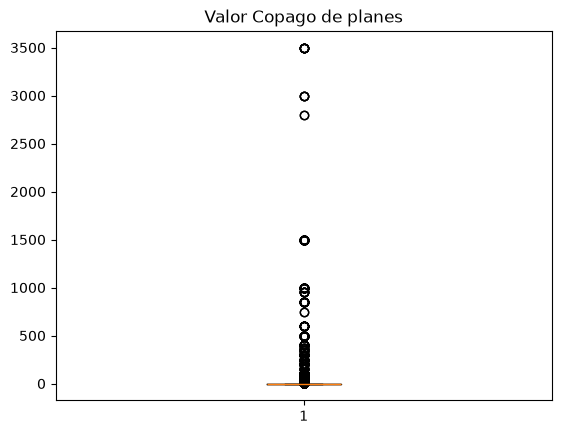

In [122]:
fig1, ax1 = plt.subplots()
ax1.set_title('Valor Copago de planes')
data_copago = [row[0] for row in planes_beneficio.select('valorCopago').dropna().collect()]
ax1.boxplot(data_copago)
plt.show()

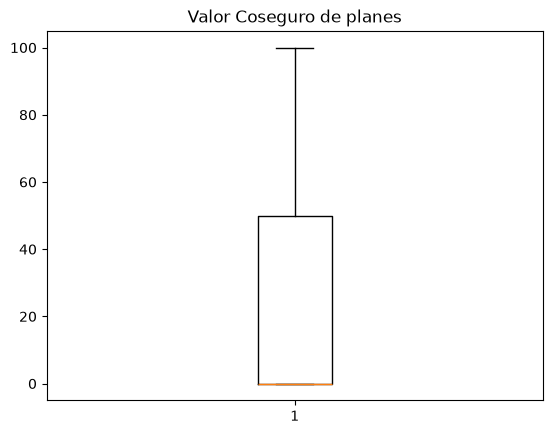

In [123]:
fig1, ax1 = plt.subplots()
ax1.set_title('Valor Coseguro de planes')
data_coseguro = [row[0] for row in planes_beneficio.select('valorCoseguro').dropna().collect()]
ax1.boxplot(data_coseguro)
plt.show()

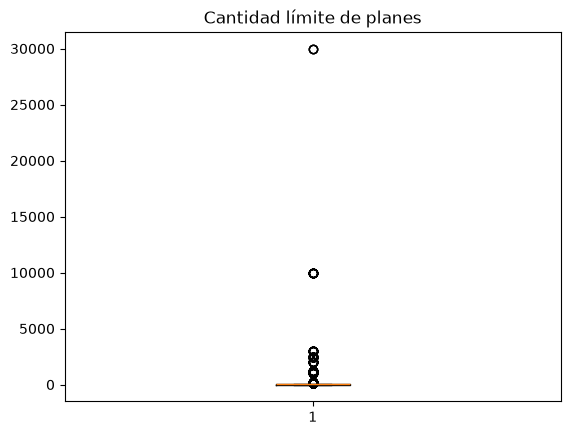

In [124]:
fig1, ax1 = plt.subplots()
ax1.set_title('Cantidad límite de planes')
data_cantidad = [row[0] for row in planes_beneficio.select('cantidadLimite').dropna().collect()]
ax1.boxplot(data_cantidad)
plt.show()

Se destaca que el 75% de los registros tienen valor de copago 0 y valor de coseguro menor a 50. La cantidad límite tiene varios faltantes, y pese a que el 75% de los registros tienen cantidad límite menor a 40, el valor máximo es 30000. Los diagramas de caja muestran que la mayoría de los planes tienen valores de 0 para valor de copago y valores menores a 40 para cantidad límite.

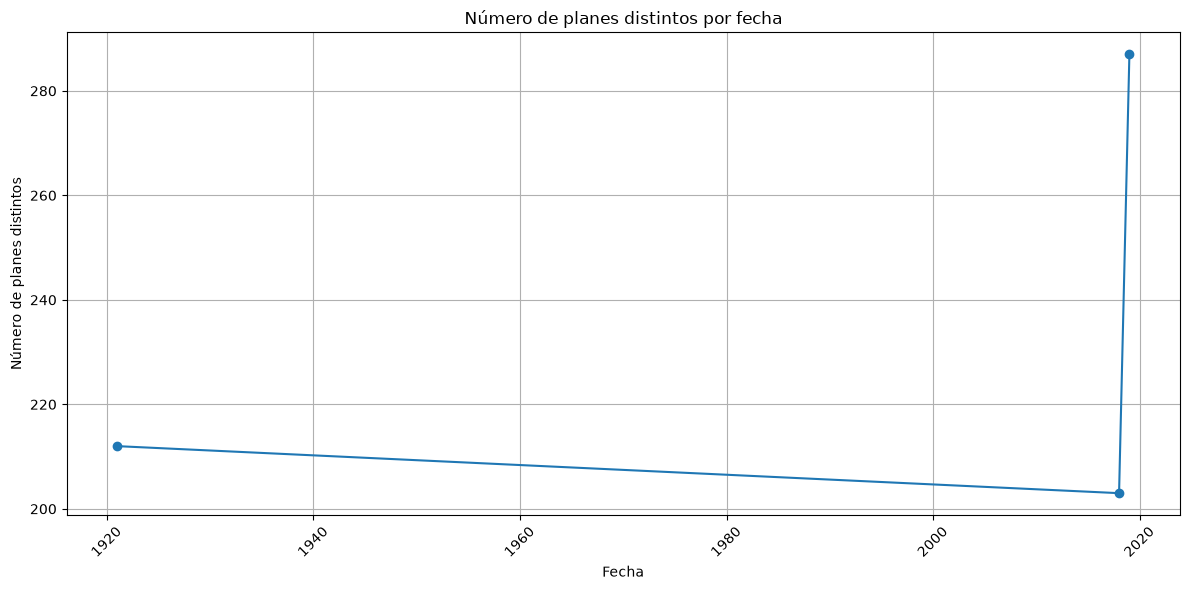

In [ ]:
planes_por_fecha = planes_beneficio.groupBy('Fecha_convertida').agg(countDistinct('IdPlan_T').alias('Numero_Planes')).orderBy('Fecha_convertida')

df_grafica = planes_por_fecha.toPandas()

plt.figure(figsize=(12, 6))
plt.plot(df_grafica['Fecha_convertida'], df_grafica['Numero_Planes'], marker='o')

plt.xlabel('Fecha')
plt.ylabel('Número de planes distintos')
plt.title('Número de planes distintos por fecha')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [129]:
planes_por_fecha.show()

+----------------+-------------+
|Fecha_convertida|Numero_Planes|
+----------------+-------------+
|      1920-12-31|          212|
|      2017-12-31|          203|
|      2018-12-31|          287|
+----------------+-------------+



Todas las fechas de oferta de beneficios para un plan corresponden al día 31 y al mes 12. Existen 212 planes con fecha de oferta del año 1920, ¿esto es un error?

In [131]:
planes_beneficio.groupby("IdAreaDeServicio_T").count().orderBy("count", ascending=False).show(5)

+------------------+-----+
|IdAreaDeServicio_T|count|
+------------------+-----+
|              NULL| 2041|
|          11132018|  260|
|          44112018|  260|
|          50152017|  250|
|          38532017|  249|
+------------------+-----+
only showing top 5 rows


In [132]:
planes_beneficio.groupby("IdTipoBeneficio_T").count().orderBy("count", ascending=False).show(5)

+-----------------+-----+
|IdTipoBeneficio_T|count|
+-----------------+-----+
|             NULL| 2086|
|              640|  699|
|              190|  606|
|              455|  602|
|              595|  591|
+-----------------+-----+
only showing top 5 rows


In [133]:
planes_beneficio.groupby("IdNivelServicio_T").count().orderBy("count", ascending=False).show(5)

+-----------------+-----+
|IdNivelServicio_T|count|
+-----------------+-----+
|                1|12045|
|                3|12028|
|                2|11963|
+-----------------+-----+



El valor más común para el identificador del área de servicio y del tipo de beneficio en los planes es nulo, sin embargo se esperaría que todos los planes tuvieran el identificador del área y del tipo de beneficio asociado. También se evidencia que hay una distribución equitativa entre los 3 niveles de servicio respecto al número de planes en cada nivel.

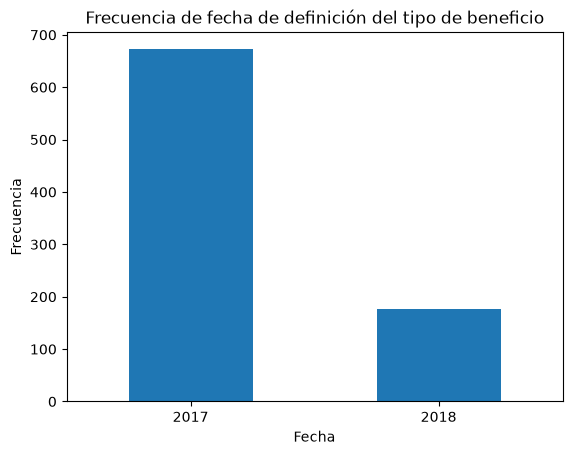

In [134]:
tipos_beneficio.toPandas()['Fecha'] \
    .value_counts() \
    .sort_index() \
    .plot(kind='bar')

plt.xlabel('Fecha')
plt.ylabel('Frecuencia')
plt.title('Frecuencia de fecha de definición del tipo de beneficio')
plt.xticks(rotation=0)
plt.show()

Se definieron más beneficios en el año 2017 en comparación al año 2018.

## Análisis de calidad de datos


### Completitud

In [136]:
def contar_vacios(df):
    resultados = []
    for c in df.columns:
        vacios = df.filter(df[c].isNull()).count()
        if vacios!=0:
            print('número de vacíos para columna '+c+': '+str( vacios ))
            resultados.append(vacios)
    return resultados

def cardinalidad(df):
    resultado = {}
    for c in df.columns:
        cardinalidad = df.select(col(c)).distinct().count()
        if cardinalidad>=df.count()*0.5:
            resultado[c] = cardinalidad
    return resultado

In [137]:
#Completitud
columnas_vacias_areas = contar_vacios(areas_servicio)
columnas_alta_cardinalidad_areas = cardinalidad(areas_servicio)
columnas_alta_cardinalidad_areas

número de vacíos para columna IdAreaDeServicio_T: 6288
número de vacíos para columna IdGeografia_T: 6378
número de vacíos para columna Area: 2407
número de vacíos para columna Densidad: 2407


{}

In [ ]:
columnas_vacias_condiciones = contar_vacios(condiciones_pago)
columnas_alta_cardinalidad_condiciones = cardinalidad(condiciones_pago)
columnas_alta_cardinalidad_condiciones

{'IdCondicionesDePago_T': 23, 'Descripcion': 17}

In [139]:
columnas_vacias_planes = contar_vacios(planes_beneficio)
columnas_alta_cardinalidad_planes = cardinalidad(planes_beneficio)
columnas_alta_cardinalidad_planes

número de vacíos para columna IdTipoBeneficio_T: 2086
número de vacíos para columna IdAreaDeServicio_T: 2041
número de vacíos para columna cantidadLimite: 30571


{}

In [140]:
columnas_vacias_tipos = contar_vacios(tipos_beneficio)
columnas_alta_cardinalidad_tipos = cardinalidad(tipos_beneficio)
columnas_alta_cardinalidad_tipos

{}

In [170]:
planes_beneficio.filter(col('IdPlan_T') == "").count()

2053

Para las áreas de servicio las columnas con valores nulos son IdAreaDeServicio_T (6288 faltantes), IdGeografia_T (6378), Area (2407) y Densidad (2407). Contar con información completa del IdAreaDeServicio_T y IdGeografia_T es esencial para los análisis requeridos por RaSA. Para los planes, las columnas con nulos son IdTipoBeneficio_T (2086), IdAreaDeServicio_T (2041) y cantidadLimite (30571).

Respecto a la cardinalidad, las columnas de IdCondicionesDePago_T y Descripcion tienen una cardinalidad superior al 50% en condiciones de pago.

Adicionalmente hay 2053 planes con ID en blanco

### Unicidad

In [143]:
#Unicidad
unicos_areas = areas_servicio.dropDuplicates().count()
188815 - unicos_areas

43573

In [145]:
unicos_condiciones = condiciones_pago.dropDuplicates().count()
31 - unicos_condiciones

7

In [147]:
unicos_planes = planes_beneficio.dropDuplicates().count()
36036 - unicos_planes

8493

In [148]:
unicos_tipos = tipos_beneficio.dropDuplicates().count()
849 - unicos_tipos

271

Existen 43573 registros duplicados para áreas de servicio, 7 para condiciones de pago, 8493 para planes de beneficios y 271 para tipos de beneficios.

In [158]:
repetidos = areas_servicio.groupBy("IdAreaDeServicio_T").count().filter(col("count") > 1).select("IdAreaDeServicio_T")
areas_servicio.join(repetidos, on="IdAreaDeServicio_T", how="inner").orderBy("IdAreaDeServicio_T").show(truncate=False)

+------------------+-----------------------------+-------------+---------------------+--------+------------+-----+--------+-----+
|IdAreaDeServicio_T|NombreAreaDeServicio         |IdGeografia_T|Condado              |Estado  |PoblacionAct|Area |Densidad|Fecha|
+------------------+-----------------------------+-------------+---------------------+--------+------------+-----+--------+-----+
|12018             |NoVa10207VA0380001-0620189007|51153        |Prince William County|Virginia|484472.0    |338.0|1433.0  |2018 |
|12018             |NoVa10207VA0380001-0620189007|51059        |Fairfax County       |Virginia|1139720.0   |396.0|2878.0  |2018 |
|12018             |NoVa10207VA0380001-0620189007|51013        |Arlington County     |Virginia|232965.0    |26.0 |8960.0  |2018 |
|12018             |NoVa10207VA0380001-0620189007|51610        |Falls Church City    |Virginia|14309.0     |NULL |NULL    |2018 |
|12018             |NoVa10207VA0380001-0620189007|51600        |Fairfax City         |Virg

In [ ]:
duplicados = areas_servicio.groupBy('Condado', 'Estado', 'PoblacionAct', 'Area', 'Densidad').count().filter(col('count') > 1)
duplicados.show()

+--------------------+--------------+------------+------+--------+-----+
|             Condado|        Estado|PoblacionAct|  Area|Densidad|count|
+--------------------+--------------+------------+------+--------+-----+
|     Monmouth County|    New Jersey|    645354.0| 472.0|  1367.0|  296|
|      Clinton County|      Michigan|     79426.0| 575.0|   138.0|  222|
|       Medina County|          Ohio|    183092.0| 423.0|   433.0|  125|
|       Powell County|       Montana|      6999.0|2326.0|     3.0|   83|
|     Flathead County|       Montana|    108454.0|5099.0|    21.0|   88|
|      Edwards County|        Kansas|      2832.0| 622.0|     5.0|   98|
|    Alexander County|North Carolina|     36644.0| 263.0|   139.0|  171|
|     Davidson County|North Carolina|    170637.0| 567.0|   301.0|  164|
|          Lee County|         Texas|     17706.0| 629.0|    28.0|  175|
|       Phelps County|      Missouri|     44937.0| 673.0|    67.0|  121|
|        Osage County|      Missouri|     13379.0| 

In [157]:
areas_servicio.filter(col('Condado') == 'Monmouth County').filter(col('PoblacionAct') == 645354) \
    .filter(col('Estado') == 'New Jersey').filter(col('Area') == 472) \
    .filter(col('Densidad') == 1367).agg(countDistinct('IdAreaDeServicio_T')).show()

+----------------------------------+
|count(DISTINCT IdAreaDeServicio_T)|
+----------------------------------+
|                               165|
+----------------------------------+



Existen múltiples combinaciones de condado, estado, población actual, área y densidad con numerosos registros de área de servicio. Se debe recibir aclaración por parte del negocio acerca de la validez de que existan diferentes áreas de servicio con los mismos valores para todas estas 5 columnas. Por ejemplo, de los 296 registros de áreas que tienen condado Monmouth County, estado New Jersey, población actual de 645354 personas, área de 472 millas cuadradas y densidad de 1367 personas por milla cuadrada, solo 165 registros tienen identificadores de área de servicio únicos.

In [159]:
repetidos = condiciones_pago.groupBy("IdCondicionesDePago_T").count().filter(col("count") > 1).select("IdCondicionesDePago_T")
condiciones_pago.join(repetidos, on="IdCondicionesDePago_T", how="inner").orderBy("IdCondicionesDePago_T").show(truncate=False)

+---------------------+-------------------------------+--------+
|IdCondicionesDePago_T|Descripcion                    |Tipo    |
+---------------------+-------------------------------+--------+
|27                   |Coinsurance after deductible   |Coseguro|
|27                   |Coinsurance after deductible   |Coseguro|
|45                   |Coinsurance                    |Coseguro|
|45                   |Coinsurance                    |Coseguro|
|51                   |No Charge                      |Copago  |
|51                   |No Charge                      |Copago  |
|119                  |Copay per Day with deductible  |Copago  |
|119                  |Copay per Day with deductible  |Copago  |
|204                  |Copay per Day                  |Copago  |
|204                  |Copay per Stay after deductible|Copago  |
|204                  |Copay per Stay after deductible|Copago  |
|207                  |No Charge after deductible     |Copago  |
|207                  |No

No todos los duplicados del ID de condición de pago tienen los mismos valores para el resto de columnas. Existen tres registros con ID 204, tipo Copago pero diferente descripción. ¿Cuál es la correcta?

### Consistencia

In [177]:
planes_beneficio.join(tipos_beneficio, on='IdTipoBeneficio_T', how='left_anti').select('IdTipoBeneficio_T').distinct().count()

108

In [180]:
planes_beneficio.join(areas_servicio, on='IdAreaDeServicio_T', how='left_anti').select('IdAreaDeServicio_T').distinct().count()

1098

In [181]:
planes_beneficio.join(condiciones_pago, planes_beneficio.IdCondicionDePagoCopago_T == condiciones_pago.IdCondicionesDePago_T, 'left_anti').select('IdAreaDeServicio_T').distinct().count()

0

In [183]:
planes_beneficio.join(condiciones_pago, planes_beneficio.IdCondicionDePagoCoseguro_T == condiciones_pago.IdCondicionesDePago_T, 'left_anti').select('IdAreaDeServicio_T').distinct().count()

0

Además de las observaciones relacionadas con la consistencia de los datos que ya se presentaron anteriormente, se evidencia que existen 108 IDs de tipo de beneficio que aparecen en la tabla de planes pero no en la tabla de tipos de beneficios, y 1098 IDs de área de servicio que aparecen en la tabla de planes pero no en la tabla de áreas de servicio. 

### Validez

In [33]:
areas_servicio.filter(col('IdGeografia_T').isNotNull()).groupBy('IdGeografia_T', 'Condado').agg(countDistinct('PoblacionAct').alias('Total_Poblaciones')
).filter(col('Total_Poblaciones') > 1
).orderBy(col('Total_Poblaciones').desc()).show()

+-------------+--------------------+-----------------+
|IdGeografia_T|             Condado|Total_Poblaciones|
+-------------+--------------------+-----------------+
|        20109|        Logan County|                2|
|        20081|      Haskell County|                2|
|        23007|     Franklin County|                2|
|        29091|       Howell County|                2|
|        54043|      Lincoln County|                2|
|        29197|     Schuyler County|                2|
|        17045|        Edgar County|                2|
|        21031|       Butler County|                2|
|        51149|Prince George County|                2|
|        40141|      Tillman County|                2|
|        26159|    Van Buren County|                2|
|        46025|        Clark County|                2|
|        21223|      Trimble County|                2|
|        29119|     McDonald County|                2|
|        39095|        Lucas County|                2|
|        2

In [34]:
areas_servicio.filter(col('IdGeografia_T').isNotNull()).groupBy('IdGeografia_T', 'Condado').agg(countDistinct('Area').alias('Total_Areas')
).filter(col('Total_Areas') > 1
).orderBy(col('Total_Areas').desc()).show()

+-------------+-----------------+-----------+
|IdGeografia_T|          Condado|Total_Areas|
+-------------+-----------------+-----------+
|        55001|     Adams County|          2|
|        18017|      Cass County|          2|
|        18055|    Greene County|          2|
|        12075|      Levy County|          2|
|        37101|  Johnston County|          2|
|        29055|  Crawford County|          2|
|        29019|     Boone County|          2|
|        21031|    Butler County|          2|
|        18037|    Dubois County|          2|
|        46081|  Lawrence County|          2|
|        29171|    Putnam County|          2|
|        46025|     Clark County|          2|
|        12045|      Gulf County|          2|
|        12086|Miami-Dade County|          2|
|        17025|      Clay County|          2|
|        18079|  Jennings County|          2|
|        40007|    Beaver County|          2|
|        38023|    Divide County|          2|
|        30103|  Treasure County| 

Además de las observaciones relacionadas con la validez de los datos que ya se presentaron anteriormente, se evidencia que existen registros con el mismo IDs de condado y nombre del condado, pero con diferentes poblaciones actuales y áreas en millas cuadradas.

### Otras exploraciones

In [188]:
planes_beneficio.groupBy('IdPlan_T').agg(countDistinct('IdProveedor_T').alias('Total_Proveedores')) \
    .filter(col('Total_Proveedores') > 1).orderBy(col('Total_Proveedores').desc()).show()

+--------+-----------------+
|IdPlan_T|Total_Proveedores|
+--------+-----------------+
|        |              101|
+--------+-----------------+



Solo los registros que comparten el identificador del plan en blanco tienen diferentes proveedores. Para los registros que sí tienen identificador del plan, ninguno tiene más de un proveedor asociado.

In [21]:
from pyspark.sql.types import DecimalType, DoubleType

df_corr = planes_beneficio
for field in planes_beneficio.schema.fields:
    if isinstance(field.dataType, DecimalType):
        df_corr = df_corr.withColumn(field.name, col(field.name).cast(DoubleType()))

corr = df_corr.toPandas().corr(method='pearson', numeric_only=True)
corr.style.background_gradient(cmap='coolwarm')

,IdTipoBeneficio_T,IdAreaDeServicio_T,IdCondicionDePagoCopago_T,IdCondicionDePagoCoseguro_T,IdNivelServicio_T,IdProveedor_T,valorCopago,valorCoseguro,cantidadLimite
IdTipoBeneficio_T,1.000000,-0.033967,-0.051901,-0.024140,0.006969,-0.013036,0.000505,0.044677,0.020959
IdAreaDeServicio_T,-0.033967,1.000000,0.019745,0.072562,-0.001951,0.727336,-0.016810,0.046057,0.083457
IdCondicionDePagoCopago_T,-0.051901,0.019745,1.000000,0.557733,-0.135093,0.020342,0.030092,-0.655339,-0.010987
IdCondicionDePagoCoseguro_T,-0.024140,0.072562,0.557733,1.000000,0.336831,0.082064,-0.079598,0.024006,-0.000199
IdNivelServicio_T,0.006969,-0.001951,-0.135093,0.336831,1.000000,-0.001193,-0.036932,0.510521,-0.000020
IdProveedor_T,-0.013036,0.727336,0.020342,0.082064,-0.001193,1.000000,-0.009529,0.048411,0.076964
valorCopago,0.000505,-0.016810,0.030092,-0.079598,-0.036932,-0.009529,1.000000,-0.008779,0.002909
valorCoseguro,0.044677,0.046057,-0.655339,0.024006,0.510521,0.048411,-0.008779,1.000000,0.004192
cantidadLimite,0.020959,0.083457,-0.010987,-0.000199,-0.000020,0.076964,0.002909,0.004192,1.000000


Se evidencia que existen correlaciones importantes entre el ID de condición de pago coseguro y el Id de condición de pago copago (0.558) y entre el ID del proveedor y el ID del área de servicio (0.727). 

In [12]:
from pyspark.sql.functions import collect_set

planes_beneficio.filter(col("IdAreaDeServicio_T") > 0).groupBy("IdAreaDeServicio_T").agg(collect_set("IdProveedor_T").alias("Proveedores por área")).orderBy("IdAreaDeServicio_T").show(truncate=False)

+------------------+--------------------+
|IdAreaDeServicio_T|Proveedores por área|
+------------------+--------------------+
|12018             |[10207]             |
|42018             |[10207]             |
|52018             |[10207]             |
|62018             |[10207]             |
|82018             |[10207]             |
|112018            |[10207]             |
|122018            |[10207]             |
|142018            |[10207]             |
|152018            |[10207]             |
|162018            |[10207]             |
|242017            |[11269]             |
|252017            |[11269]             |
|262017            |[11269]             |
|272017            |[11269]             |
|282017            |[11269]             |
|292017            |[11269]             |
|302017            |[11269]             |
|312017            |[11269]             |
|322017            |[11269]             |
|332017            |[11269]             |
+------------------+--------------

In [194]:
planes_beneficio.groupBy('IdAreaDeServicio_T').agg(countDistinct('IdProveedor_T').alias('Total_Proveedores')) \
    .filter(col('Total_Proveedores') > 1).orderBy(col('Total_Proveedores').desc()).show()

+------------------+-----------------+
|IdAreaDeServicio_T|Total_Proveedores|
+------------------+-----------------+
|              NULL|               99|
+------------------+-----------------+



Se comprueba que solo los registros sin identificador del área de servicio tienen diferentes proveedores, mientras que las áreas con identificador tienen solo un identificador de proveedor asociado. 

In [196]:
planes_beneficio.filter(col("IdCondicionDePagoCopago_T") > 0).groupBy("IdCondicionDePagoCopago_T").agg(collect_set("IdCondicionDePagoCoseguro_T").alias("Condiciones de Pago Coseguro")).orderBy("IdCondicionDePagoCopago_T").show(truncate=False)

+-------------------------+----------------------------+
|IdCondicionDePagoCopago_T|Condiciones de Pago Coseguro|
+-------------------------+----------------------------+
|17                       |[36]                        |
|34                       |[18, 36, 9, 27, 45]         |
|51                       |[18, 36, 9, 27, 45]         |
|68                       |[36, 27]                    |
|85                       |[36]                        |
|102                      |[36, 27]                    |
|136                      |[27, 45]                    |
|153                      |[36, 27]                    |
|170                      |[18, 36, 27, 45]            |
|187                      |[36, 27, 45]                |
|204                      |[36, 27]                    |
|207                      |[18, 36, 27, 45]            |
|221                      |[27, 45]                    |
|238                      |[18, 36, 9, 27, 45]         |
+-------------------------+----

Se observa que algunas condiciones de pago copago solo tienen asociado un ID para la condición de pago coseguro, por ejemplo el ID de pago copago 17 (Copay per Day after deductible) solo está asociado con el ID 36 de pago coseguro (Not Applicable). Se debe consultar con el negocio si existen combinaciones de IDs de condiciones de pago copago y coseguro que no deben aparecer asociadas en los planes.

In [13]:
planes_beneficio.filter(col("IdTipoBeneficio_T") > 0).groupBy("IdTipoBeneficio_T").agg(collect_set("IdProveedor_T").alias("Proveedores por tipo de beneficio")).orderBy("IdTipoBeneficio_T").show(truncate=False)

+-----------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|IdTipoBeneficio_T|Proveedores por tipo de beneficio                                                                                                                                                                                                                                                                                                                                                                               

In [17]:
planes_beneficio.filter(col('IdTipoBeneficio_T') == 5).groupBy("IdProveedor_T").agg(collect_set("valorCopago").alias("Valor Copago por proveedor")).show(truncate=False)

+-------------+--------------------------+
|IdProveedor_T|Valor Copago por proveedor|
+-------------+--------------------------+
|87571        |[0]                       |
|14002        |[0]                       |
|33602        |[0]                       |
|66252        |[0]                       |
|31195        |[0]                       |
|91450        |[0]                       |
|19636        |[0]                       |
|28162        |[0]                       |
|93091        |[0, 75]                   |
|83761        |[0]                       |
|37651        |[0]                       |
|67243        |[0]                       |
|29698        |[0]                       |
|16842        |[0]                       |
|32753        |[0]                       |
|40047        |[0]                       |
|96751        |[0]                       |
|38345        |[0]                       |
|31274        |[0]                       |
|91661        |[0]                       |
+----------

In [18]:
planes_beneficio.filter(col('IdTipoBeneficio_T') == 5).groupBy("IdProveedor_T").agg(collect_set("valorCoseguro").alias("Valor Coseguro por proveedor")).show(truncate=False)

+-------------+----------------------------+
|IdProveedor_T|Valor Coseguro por proveedor|
+-------------+----------------------------+
|87571        |[0]                         |
|14002        |[0]                         |
|33602        |[0]                         |
|66252        |[0]                         |
|31195        |[0]                         |
|91450        |[0]                         |
|19636        |[0]                         |
|28162        |[0]                         |
|93091        |[0, 100]                    |
|83761        |[0]                         |
|37651        |[0]                         |
|67243        |[0]                         |
|29698        |[0]                         |
|16842        |[0]                         |
|32753        |[0]                         |
|40047        |[0]                         |
|96751        |[0, 100, 25]                |
|38345        |[0]                         |
|31274        |[0]                         |
|91661    

Existen proveedores con valores diferentes para valor de copago y coseguro de un tipo de beneficio. Por ejemplo, para el tipo de beneficio con ID 5 el proveedor 93091 tiene valores de copago de 0 y 75, y el proveedor 91661 tiene valores de coseguro de 10, 30, 50 y 100. ¿Esto tiene sentido? ¿Corresponde a un comportamiento desleal?

In [22]:
df_corr = areas_servicio
for field in areas_servicio.schema.fields:
    if isinstance(field.dataType, DecimalType):
        df_corr = df_corr.withColumn(field.name, col(field.name).cast(DoubleType()))

corr = df_corr.toPandas().corr(method='pearson', numeric_only=True)
corr.style.background_gradient(cmap='coolwarm')

,IdAreaDeServicio_T,IdGeografia_T,PoblacionAct,Area,Densidad,Fecha
IdAreaDeServicio_T,1.000000,-0.045052,-0.004567,-0.175746,0.124930,-0.000630
IdGeografia_T,-0.045052,1.000000,-0.024692,0.071512,-0.007512,0.063357
PoblacionAct,-0.004567,-0.024692,1.000000,0.001816,0.086849,0.012855
Area,-0.175746,0.071512,0.001816,1.000000,-0.087442,-0.006350
Densidad,0.124930,-0.007512,0.086849,-0.087442,1.000000,0.000222
Fecha,-0.000630,0.063357,0.012855,-0.006350,0.000222,1.000000


In [28]:
areas_servicio.groupBy('IdGeografia_T').agg(countDistinct('Condado').alias('Total_Condados')) \
    .filter(col('Total_Condados') > 1).orderBy(col('Total_Condados').desc()).show()

+-------------+--------------+
|IdGeografia_T|Total_Condados|
+-------------+--------------+
|         NULL|           987|
|        51057|             2|
|        12057|             2|
|        51183|             2|
|        39009|             2|
|        51171|             2|
|        51087|             2|
|        45009|             2|
|        12021|             2|
|        51135|             2|
|        54039|             2|
|        39153|             2|
|        15003|             2|
|        39039|             2|
|        54069|             2|
|        39033|             2|
|        39057|             2|
|        39081|             2|
|        30003|             2|
|        39099|             2|
+-------------+--------------+
only showing top 20 rows


In [29]:
areas_servicio.filter(col('IdGeografia_T') == 51057).groupBy("IdGeografia_T").agg(collect_set("Condado").alias("Condados")).show(truncate=False)

+-------------+--------------------------------+
|IdGeografia_T|Condados                        |
+-------------+--------------------------------+
|51057        |[Essex County, Champaign County]|
+-------------+--------------------------------+



Según el diccionario de datos IdGreografia_T es el identificador del condado, sin embargo existen identificadores de condado con múltiples nombres. Por ejemplo el identificador 51057 tiene dos condados asociados, ¿esto tiene sentido?

### Integración de Fuentes y Llaves de Enlace

En cumplimiento de los requerimientos de la fase de entendimiento, a continuación se consolida la matriz formal de enlace entre la tabla transaccional central de planes y las tablas satélite/maestras, identificando las llaves candidatas y los hallazgos de integridad referencial:

| Tabla Origen (Planes - F3) | Llave de Cruce | Tabla Destino | Llave Destino | Integridad / Observación Detectada |
| :--- | :--- | :--- | :--- | :--- |
| `FuentePlanesBeneficio_Copia_E` | `IdAreaDeServicio_T` | `FuenteAreasDeServicio_Copia_E` (F1) | `IdAreaDeServicio_T` | **Inconsistencia:** Existen 1.098 IDs huérfanos en F3. En el modelado dimensional requerirá una dimensión comodín `Desconocido (0)`. |
| `FuentePlanesBeneficio_Copia_E` | `IdTipoBeneficio_T` | `FuenteTiposBeneficio_Copia_E` (F2) | `IdTipoBeneficio_T` | **Inconsistencia:** 108 IDs huérfanos en F3 que deben ser excluidos del análisis según directriz del negocio. |
| `FuentePlanesBeneficio_Copia_E` | `IdCondicionDePagoCopago_T` | `FuenteCondicionesDePago_Copia_E` (F4) | `IdCondicionesDePago_T` | Cruce consistente; requiere unificación previa de etiquetas (`Copago` vs. `Copagado`). |
| `FuentePlanesBeneficio_Copia_E` | `IdCondicionDePagoCoseguro_T` | `FuenteCondicionesDePago_Copia_E` (F4) | `IdCondicionesDePago_T` | Cruce consistente; requiere unificación previa de etiquetas (`Coseguro` vs. `Coseguridad`). |

### Conclusiones

**Conclusiones generales:**

1. En la tabla de áreas de servicio se encuentra la información relacionada con el área de servicio, su identificador, su condado, estado, área en millas cuadradas, población actual, densidad poblacional y fecha de creación. Una fila representa un área de servicio en un condado con cierta población, área y densidad.
2. La tabla de condiciones de pago contiene el identificador de la condición de pago, su descripción y su tipo. Una fila representa una condición de pago con su descripción y tipo.
3. La tabla de planes contiene información de un plan a partir del tipo de beneficio, del área de servicio, de la condicion de pago Copago, de la condicion de pago Coseguro, del nivel de servicio, del identificador del plan, la fecha de oferta del beneficio para ese plan, del proveedor del plan,  valor del copago, valor del coseguro y la cantidad límite del tipo de beneficio, es decir, la cantidad máxima de unidades del beneficio a las cuales el usuario puede acceder en un año. Una fila representa un plan con un tipo de beneficio, un área de servicio, una condición de pago Copago, una condición de pago Coseguro, un proveedor del plan y un nivel de servicio.
4. La tabla de tipos de beneficio contiene información del identificador del tipo de beneficio, del nombre del tipo de beneficio, de la unidad en la que se expresa el límite, si es beneficio esencial de salud, si el seguro lo cubre, si tiene límite cuantitativo, si está excluido del desembolso máximo dentro de la red, si está excluido del desembolso máximo fuera de la red y de la fecha en que se define el tipo de beneficio. Una fila representa un tipo de beneficio e incluye las condiciones asociadas a su beneficio, cobertura del seguro, límite y desembolsos dentro y fuera de la red.
5. ¿Qué significan los identificadores 1, 2 y 3 para el nivel de servicio de los planes?
6. ¿Cuál es la unidad de valorCopago y ValorCoseguro? 
7. ¿Existen combinaciones de características que no puedan aplicar al mismo tipo? (Por ejemplo, un tipo de beneficio no puede ser un beneficio esencial de salud y no estar cubierto por el seguro)
8. ¿Por qué las fechas de las áreas de servicio y de tipos de beneficio solo incluyen el año?


**Conclusiones de reglas de negocio:**

1. La regla 1 no se puede corroborar con la información disponible, puesto que con ella no es posible determinar cuáles son todos los condados del país. Se requiere de una tabla que contenga todos los condados del país con sus identificadores para concluir si los 4252 valores únicos encontrados para el identificador del condado corresponden a 4252 condados que tiene el país en total.
2. Para corroborar el cumplimiento de la regla 2 se requiere aclaración para determinar de qué forma debe relacionarse el historial de los tipos de beneficio con los planes. Dado que los identificadores de tipos de beneficios tienen múltiples valores asociados a si el beneficio tiene un límite cuantitativo por el histórico de cambios en los tipos de beneficio, no es posible determinar cuál registro en específico del histórico corresponde a las características que aplicaban en el momento en el que se ofreció un plan. Tampoco es posible realizar una asociación entre la fecha de oferta del beneficio en un plan con la fecha en que se definió el tipo de beneficio porque solo se conoce el año y existen múltiples registros para un tipo de beneficio en un mismo año.
3. La tercera regla no se cumple porque ninguna de las dos fuentes de áreas de servicio y tipos de beneficio comparte información más allá del año 2018.
4. La regla 4 no se cumple porque existen 178 identificadores únicos de tipo de beneficio (8 valores más de lo que indica la regla) y si bien existen 5409 identificadores únicos para área de servicio, existen áreas sin identificador.
5. La regla 5 no se cumple en su totalidad ya que el valor máximo de copago para el 2018 es 3500, no 3300.
6. No se cumple con la regla 6 porque se encontraron 203 identificadores únicos de plan para el 2017 y 287 para el 2018.
7. Respecto a la regla 7, asumiendo que Copagado y Copago tienen el mismo significado, sí existen 15 condiciones de copago. Existen 5 condiciones clasificadas con tipo Coseguro, pero si Coseguridad tiene el mismo significado entonces existirían 6 condiciones, no 5. Se debe recibir claridad acerca de si Coseguridad corresponde a Coseguro y si Copagado corresponde a Copago.

**Conclusiones de calidad:**
1. Para las áreas de servicio se encontraron valores nulos para IdAreaDeServicio_T (6288 nulos), IdGeografia_T (6378 nulos), Area (2407 nulos) y Densidad (2407 nulos). Para los planes, las columnas con nulos son IdTipoBeneficio_T (2086 nulos), IdAreaDeServicio_T (2041 nulos) y cantidadLimite (30571 nulos).
2. Las únicas columnas con una cardinalidad superior al 50% son las columnas de IdCondicionesDePago_T y Descripcion en la tabla de condiciones de pago.
3. Existen 2053 planes con ID en blanco.
4. Existen valores negativos para el área en millas cuadradas en la tabla de áreas de servicio, lo cual no tiene sentido.
3. El 75% de los registros de planes tienen valor de copago 0 y valor de coseguro menor a 50. Además, para los planes que sí tienen una cantidad límite, el 75% tienen una cantidad límite menor a 40.
4. Existen 43573 registros completamente duplicados para áreas de servicio, 7 para condiciones de pago, 8493 para planes de beneficios y 271 para tipos de beneficios. ¿Es posible eliminarlos?
5. Existen múltiples combinaciones de condado, estado, población actual, área y densidad con numerosos registros de área de servicio. Se debe recibir aclaración por parte del negocio acerca de la validez de que existan diferentes áreas de servicio en el mismo condado.
6. Existen tres registros con ID 204 para condición de pago, todos con tipo Copago pero diferente descripción. ¿Cuál es la descripción correcta?
7. Existen 108 IDs de tipo de beneficio que aparecen en la tabla de planes pero no en la tabla de tipos de beneficios, y 1098 IDs de área de servicio que aparecen en la tabla de planes pero no en la tabla de áreas de servicio. Esto no tiene sentido en el contexto del problema.
8. Algunas condiciones de pago copago de la tabla de planes solo aparecen combinados con un ID específico para la condición de pago coseguro. ¿Existen combinaciones de IDs de condiciones de pago copago y coseguro que no deben aparecer asociadas en los planes?
9. Existen proveedores con valores diferentes para el valor de copago y de coseguro de un mismo tipo de beneficio. ¿Esto tiene sentido? ¿Corresponde a un comportamiento desleal?
10. Existen identificadores de condado con múltiples nombres de condado. ¿Esto tiene sentido?
11. Hay dos valores que indican que el tipo de beneficio sí tiene límite cuantitativo (Yes y Si) y dos valores que indican que no se tiene límite cuantitativo (No y Nein) ¿Cuál de ellos es el correcto para el negocio?
12. Existen registros de áreas de servicio con fecha de creación 1800 y planes con fecha de oferta del año 1920. ¿Esto es un error?
13. Existen formatos diferentes para la fecha de oferta del plan. ¿Cuál es el correcto?
14. Hay múltiples áreas con una población de 47.280.300.000 personas. ¿Esto tiene sentido, o se trata de un error de digitación? Para estos registros el área en millas cuadradas es 1729 y hay 2735 habitantes por milla cuadrada, por lo cual el número de habitantes esperado debería ser 4.728.815.
15. Existen 769 registros de áreas de servicio con densidad poblacional igual a 0. Para estas áreas la población actual es menor al área en millas cuadradas y la densidad debería ser un decimal que empieza con 0. ¿El negocio redondea a 0 la densidad para estos casos?
16. Existen registros con el mismo identificador de condado y nombre del condado, pero con diferentes poblaciones actuales y áreas en millas cuadradas. ¿Esto tiene sentido?

**Conclusiones de consultoría**
Teniendo en cuenta los requerimientos de RaSA, se considera que si bien es posible llevar a cabo una solución para identificar el comportamiento desleal de proveedores, analizar la cobertura de los planes por área y proveedor, identificar concentraciones de planes inadecuadas según la población y la evolución de costos de tipos de beneficios y planes, se requiere de la resolución de las dudas presentadas anteriormente por parte del negocio para construir una solución robusta. Es esencial que el negocio disponga de la información de las tablas transaccionales reales y no de copias, para identificar si los problemas encontrados en los datos se deben a que las tablas analizadas son copias de las tablas transaccionales originales. Más aún,  dado que las soluciones involucran tableros de control, es importante contar con información del significado de los identificadores disponibles. Por ejemplo, para consultar información relacionada a un proveedor en un tablero de control, lo ideal es que sea posible consultar por su nombre y no por el identificador que se maneja internamente a nivel transaccional.


Teniendo en cuenta los requerimientos planteados por RaSA, se evaluó la viabilidad técnica para responder a cada una de las 4 preguntas de negocio a partir del estado actual de las fuentes:

| Tema Analítico RaSA | Viabilidad Técnica | Retos, Supuestos y Acciones de Limpieza |
| :--- | :---: | :--- |
| **1. Comportamiento Desleal** | **Viable** | Requiere calcular la dispersión ($>20\%$) de copago y coseguro por tipo de beneficio entre proveedores. **Supuesto:** El análisis se ejecutará a nivel de `IdProveedor_T`, dado que no se cuenta con la razón social o nombre comercial en la copia de los datos. |
| **2. Cobertura de Planes** | **Viable con salvedades** | El negocio confirmó que las áreas de servicio **no cubren la totalidad de los condados del país**. Por lo tanto, el análisis medirá la cobertura relativa sobre los condados disponibles y registrados. |
| **3. Concentración de Planes** | **Viable tras limpieza** | Requiere corregir en la etapa ETL el error de digitación de la población (truncar sufijo `0001` que eleva cifras a 47 mil millones) y descartar o corregir las áreas con valores negativos en millas cuadradas. |
| **4. Evolución de Costos** | **Viable (2017 - 2018)** | El análisis temporal queda restringido al período 2017–2018 debido a la ausencia confirmada de registros del año 2019 en las fuentes compartidas. |

## Coevaluación del Trabajo en Equipo

En la siguiente matriz se presenta la coevaluación del equipo para la entrega P4 (escala de 1 a 5):

| Integrante | Cumplimiento | Calidad | Aporte | Comportamiento | Promedio |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Ximena Meléndez | 5.0 | 5.0 | 5.0 | 5.0 | 5.0 |
| Camila Pérez Cárdenas | 5.0 | 5.0 | 5.0 | 5.0 | 5.0 |
| Daniel Felipe Pérez Jaimes | 5.0 | 5.0 | 5.0 | 5.0 | 5.0 |


## Transición hacia la Entrega P5 (Modelo y Diseño ETL)

Los hallazgos identificados en esta fase P4 constituyen los insumos directos para la fase P5:
1. **Reglas de Limpieza ETL:** Truncamiento del sufijo `0001` en poblaciones, exclusión/homologación de los 108 tipos de beneficio huérfanos, y unificación de términos (`Copago`/`Copagado`, `Coseguro`/`Coseguridad`).
2. **Modelo Dimensional (Data Mart ROLAP):** Adición de un registro comodín `IdAreaDeServicio_T = 0` ("Desconocido") para albergar los 1.098 planes huérfanos sin violar la integridad referencial de la dimensión geográfica.